In [1]:
import time

import bloqade.tsim
import numpy as np
import stim
import tsim
from bloqade import squin
from cultivation import batches, circuit_path, plot, points
from tqdm import tqdm

In [2]:
@squin.kernel
def main():
    q = squin.qalloc(3)
    squin.broadcast.reset(q)
    squin.h(q[0])
    squin.t(q[0])
    squin.h(q[0])
    squin.cx(q[0], q[2])
    for i in [0, 2]:
        squin.depolarize(0.5, q[i])
        squin.cx(q[i], q[1])
    squin.measure(q[1])
    squin.cx(q[1], q[0])
    squin.broadcast.measure([q[0], q[2]])

In [3]:
c = bloqade.tsim.Circuit(main)
c

tsim.Circuit('''
R 0 1 2
H 0
T 0
H 0
CX 0 2
DEPOLARIZE1(0.5) 0
CX 0 1
DEPOLARIZE1(0.5) 2
CX 2 1
M(0) 1
CX 1 0
M(0) 0 2
''')

In [4]:
c.diagram(height=150)

In [5]:
c.diagram("zx")

'<div id="zxp-c124d465ef834f24bbd6e181a9fa386c" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [6]:
sampler = c.compile_sampler()

In [7]:
samples = sampler.sample(shots=1_000_000)
samples

array([[False, False, False],
       [ True, False, False],
       [ True,  True,  True],
       ...,
       [ True, False, False],
       [ True,  True,  True],
       [ True,  True,  True]], shape=(1000000, 3))

  0%|          | 0/18 [00:00<?, ?it/s]

  6%|▌         | 1/18 [00:00<00:15,  1.11it/s]

 11%|█         | 2/18 [00:01<00:09,  1.72it/s]

 17%|█▋        | 3/18 [00:01<00:05,  2.54it/s]

 22%|██▏       | 4/18 [00:01<00:04,  3.36it/s]

 28%|██▊       | 5/18 [00:01<00:03,  4.16it/s]

... (10 outputs left out)

 89%|████████▉ | 16/18 [00:03<00:00,  5.79it/s]

 94%|█████████▍| 17/18 [00:04<00:00,  6.49it/s]

100%|██████████| 18/18 [00:04<00:00,  6.92it/s]

100%|██████████| 18/18 [00:04<00:00,  4.33it/s]

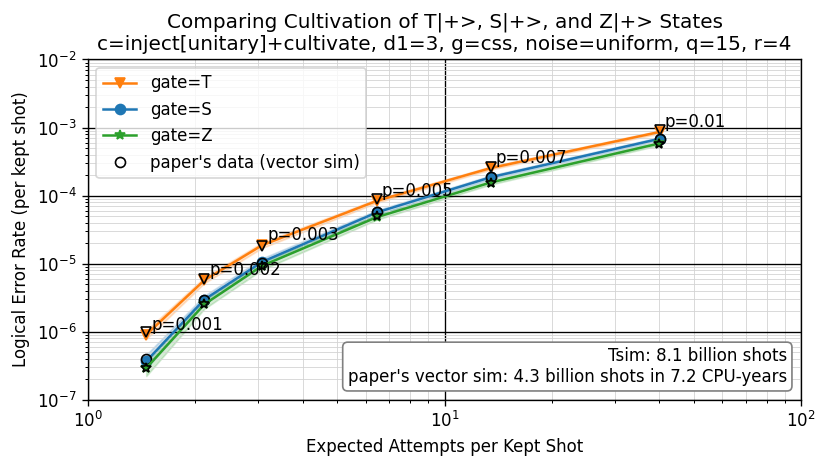

In [8]:
# Gidney, Shutty & Jones, "Magic state cultivation" (arXiv:2409.17595): cultivating T|+⟩ vs S|+⟩ vs Z|+⟩.
tally = points()  # gates T, S, Z at six noise strengths
b = 2**26
for point in tqdm(tally):
    circuit = tsim.Circuit.from_file(circuit_path(point))
    sampler = circuit.compile_detector_sampler()
    mask = np.ones(circuit.num_detectors, dtype=bool)  # postselect: keep shots where no detector fires
    for _ in batches(point):
        detectors, observables = sampler.sample(
            b, postselection_mask=mask, separate_observables=True, bit_packed=True
        )
        point.shots += b 
        point.kept += len(observables)
        point.errors += np.count_nonzero(observables)  # logical error: the observable flipped

plot(tally)

<img src="figures/bench-cult-d5.svg" alt="tally" width=850px>

In [9]:
# End-to-end d=5 cultivation (Gidney, Shutty & Jones): injection, cultivation, and escape to a d=15 surface code
circuit = tsim.Circuit.from_file("../circuits/end2end_d5_dsurface15_p0.001.stim")
sampler = circuit.compile_detector_sampler()  # on a Mac: the Apple GPU, since every component has k_max <= 11
mask = np.load("../circuits/end2end_d5_dsurface15_p0.001.postselect.npy")  # the paper's discard set (135 detectors)

n = 2**24
start = time.perf_counter()
kept = sampler.sample(n, postselection_mask=mask, append_observables=True, bit_packed=True)
seconds = time.perf_counter() - start
print(f"{n / seconds / 1e6:.0f}M shots/s, {len(kept) / n:.1%} kept")


185M shots/s, 5.2% kept


Circuits are represented as parameterized ZX diagrams, which are compiled into a contiguous datastructure for efficient sampling.

In [10]:
c.diagram("zx", scale=35);

<img src="figures/tensors.png" alt="doubled notation" width=650px>

<img src="figures/simplification.png" alt="doubled notation" width=650px>

Here, TSIM makes use of ZX diagrams in _doubled_ notation:


<img src="../figures/doubling.png" alt="doubled notation" width=650px>

In [11]:
tsim.Circuit("CNOT 0 1").diagram("zx")

'<div id="zxp-000e5a0323bd4c24901b2365dc251edd" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [12]:
tsim.Circuit("M 0").diagram("zx")

'<div id="zxp-6a733d366e9a466da91505dbffc98f5c" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [13]:
tsim.Circuit("""
    X 0
    R 0
""").diagram("zx")

'<div id="zxp-abaf4777a8544326af76c71b581e9563" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [14]:
tsim.Circuit("""
M !0
CNOT rec[-1] 1
""").diagram("zx")

'<div id="zxp-b0f64e67588e46e286cb328aa757f9f3" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

Pauli Channels are represented as parameterized Pauli vertices:

In [15]:
tsim.Circuit("""
    Z_ERROR(0.01) 0
""").diagram("zx")

'<div id="zxp-911f32eb25674a3fb0a13cfd8a6be284" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [16]:
tsim.Circuit("""DEPOLARIZE2(0.01) 0 1""").diagram("zx")

'<div id="zxp-f5f41aba4c124a9e967a35f364a522ae" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

For QEC experiments, we are often not interested in measurements themselves, but certain XOR combinations of them, referred to as _detectors_. We can directly represent detectors in ZX diagrams by applying classical XORs to measurement bits. The XOR has a simple ZX representation:

<img src="../figures/xor.png" alt="XOR gate" width=350px>

In [17]:
c = tsim.Circuit("""
    R 0 1
    H 0
    CNOT 0 1
    M 0 1
    DETECTOR rec[-1] rec[-2]
    OBSERVABLE_INCLUDE(0) rec[-1]
""")
c.diagram("zx")

'<div id="zxp-2bfc48acacde40179ac70892f1b3b0a4" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [18]:
sampler = c.compile_sampler()
sampler.sample(10)

array([[ True,  True],
       [False, False],
       [ True,  True],
       [False, False],
       [False, False],
       [ True,  True],
       [ True,  True],
       [ True,  True],
       [ True,  True],
       [False, False]])

In [19]:
detector_sampler = c.compile_detector_sampler()
detectors = detector_sampler.sample(10)

In [20]:
mask = detectors == 0

# Clifford sampling

In [21]:
p = 1e-4
stim_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    rounds=7,
    distance=7,
    before_round_data_depolarization=p,
    before_measure_flip_probability=p,
    after_clifford_depolarization=p,
    after_reset_flip_probability=p,
)
stim_sampler = stim_circuit.compile_detector_sampler()

circuit = tsim.Circuit.from_stim_program(stim_circuit)
sampler = circuit.compile_detector_sampler()

In [22]:
circuit.without_noise().diagram("timeslice-svg", height=250, rows=1)

In [23]:
circuit.diagram("zx-dets")

'<div id="zxp-17dd6a46a76249d9b5feb07e3b535332" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [24]:
num_samples = 1024**2*16

start = time.perf_counter()
samples = sampler.sample(shots=num_samples, bit_packed=True)
end = time.perf_counter()
print(f"Shots per second (Tsim): {num_samples / (end - start) / 1e6:.1f}M")

Shots per second (Tsim): 200.6M


## Non-Clifford circuits

In [25]:
c = tsim.Circuit.from_file("../circuits/msd_3.stim")
c.diagram(height=500)

In [26]:
c.diagram("zx-dets", scale_horizontally=1.3)

'<div id="zxp-ff61915129ac4d46aca34bbcdb8feb6c" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [27]:
from compilation_widget import pauli_program

pauli_program()

# Fault distance of non-Clifford circuits

The d=5 magic state cultivation circuit of [Gidney, Shutty and Jones](https://arxiv.org/abs/2409.17595) is designed for fault distance 4, a property checked on its Clifford (S-state) proxy. Chan et al. ([arxiv 2609.17706](https://arxiv.org/abs/2609.17706)) showed that the actual T-state circuit only has distance 3:

In [28]:
from tsim.experimental import shortest_errors

# Gidney et al.'s d=5 circuit: its S proxy in Stim, and with T gates in Tsim
s_proxy = stim.Circuit.from_file("../circuits/chan_cultivation/d5a19_S_inject+cultivate_p1e-3.stim")
errors_s_proxy = s_proxy.search_for_undetectable_logical_errors(
    dont_explore_detection_event_sets_with_size_above=4,
    dont_explore_edges_with_degree_above=4,
    dont_explore_edges_increasing_symptom_degree=False,
)

circuit = tsim.Circuit.from_file("../circuits/chan_cultivation/d5a19_T_inject+cultivate_p1e-3.stim")
errors = shortest_errors(circuit, max_weight=4)

print(f"fault distance of S proxy (Stim): {len(errors_s_proxy)}")
print(f"fault distance of T circuit (Tsim): {len(errors[0])}")

fault distance of S proxy (Stim): 4
fault distance of T circuit (Tsim): 3


Chan et al. restore the distance by adding 13 Z-flag qubits to the final double check:

In [29]:
# with Chan et al.'s Z flags
circuit = tsim.Circuit.from_file("../circuits/chan_cultivation/d5a19f13_T_inject+cultivate_p1e-3.stim")
errors = shortest_errors(circuit, max_weight=4)

print(f"fault distance {len(errors[0])}")

fault distance 4


# Deterministic measurements


In [30]:
from tsim.experimental import (
    count_determined_measurements,
    missing_detectors,
    nondeterministic_detectors,
)

# noiseless, without the feedforward
s_proxy = stim.Circuit.from_file("../circuits/chan_cultivation/d5a19_S_inject+cultivate_uncorrected.stim")
circuit = tsim.Circuit.from_file("../circuits/chan_cultivation/d5a19_T_inject+cultivate_uncorrected.stim")

print("measurements:", circuit.num_measurements)
print("determined parities, S proxy (Stim):", s_proxy.count_determined_measurements())
print("determined parities, T circuit (Tsim):", count_determined_measurements(circuit))

measurements: 112
determined parities, S proxy (Stim): 108
determined parities, T circuit (Tsim): 106


In [31]:
print("random detectors:", nondeterministic_detectors(circuit))
missing_detectors(circuit)

random detectors: [stim.DemTarget('D69'), stim.DemTarget('D91'), stim.DemTarget('D97'), stim.DemTarget('D102')]


stim.Circuit('''
    DETECTOR rec[-46] rec[-45] rec[-16] rec[-10]
    DETECTOR rec[-47] rec[-45] rec[-39] rec[-16] rec[-5]
''')

In [32]:
from benchmark_widget import simulator_comparison

simulator_comparison()